In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

In [24]:
%pip install --upgrade nbformat

  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
Using cached jsonschema-4.26.0-py3-none-any.whl (90 kB)
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl (18 kB)
Using cached referencing-0.37.0-py3-none-any.whl (26 kB)

   ----------- ---------------------------- 2/7 [attrs]
   ----------------- ---------------------- 3/7 [referencing]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------------- 7/7 [nbformat]

Note: you may need to restart the kernel to use updated pac

In [2]:
df = pd.read_csv('Crimes_-_2001_to_Present_20261101.csv')
display(df.head())
display(df.describe())
df2 = df.query("Year > 2025")

,ID,Date,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,FBI Code,X Coordinate,Y Coordinate,Year,Latitude,Longitude
0,14368435,10/24/2026 12:00:00 AM,042XX N MARINE DR,CRIMINAL TRESPASS,TO RESIDENCE,RESIDENCE,False,False,1915,19,46.0,26,1170986.0,1928779.0,2026,41.960047,-87.646762
1,14373382,10/24/2026 12:00:00 AM,103XX S VERNON AVE,OTHER OFFENSE,TELEPHONE THREAT,RESIDENCE,False,False,512,5,9.0,08A,1181072.0,1836493.0,2026,41.706580,-87.612529
2,14368301,10/24/2026 12:00:00 AM,085XX S CHAPPEL AVE,ASSAULT,AGGRAVATED - OTHER FIREARM,STREET,False,False,412,4,8.0,04A,1191334.0,1848657.0,2026,41.739717,-87.574557
3,14372254,10/24/2026 12:00:00 AM,0000X N UNKNOWN AVE,CRIMINAL SEXUAL ASSAULT,NON-AGGRAVATED,OTHER (SPECIFY),False,False,6100,61,0.0,02,NaN,NaN,2026,NaN,NaN
4,14368588,10/24/2026 12:00:00 AM,096XX S HOUSTON AVE,CRIMINAL DAMAGE,TO PROPERTY,RESIDENCE - GARAGE,False,False,431,4,10.0,14,1198192.0,1841661.0,2026,41.720351,-87.549665


,ID,Beat,District,Ward,X Coordinate,Y Coordinate,Year,Latitude,Longitude
count,9.517290e+05,951729.000000,951729.000000,951725.000000,9.438430e+05,9.438430e+05,951729.000000,943843.000000,943843.000000
mean,1.362126e+07,1158.118405,11.350725,23.064168,1.165477e+06,1.887359e+06,2024.372249,41.846492,-87.668236
std,7.484415e+05,733.238489,7.326161,13.972820,1.625345e+04,3.150957e+04,1.089697,0.086649,0.059181
min,2.727900e+04,111.000000,1.000000,0.000000,1.091242e+06,1.813897e+06,2023.000000,41.644590,-87.939733
25%,1.329174e+07,532.000000,5.000000,10.000000,1.154163e+06,1.860183e+06,2023.000000,41.771782,-87.709327
50%,1.364367e+07,1033.000000,10.000000,23.000000,1.167350e+06,1.893766e+06,2024.000000,41.864138,-87.660994
75%,1.400378e+07,1732.000000,17.000000,34.000000,1.176796e+06,1.910210e+06,2025.000000,41.909561,-87.626740
max,1.437570e+07,6100.000000,61.000000,50.000000,1.205119e+06,1.951517e+06,2026.000000,42.022559,-87.524529


c:\Users\User\miniconda3\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1390: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(


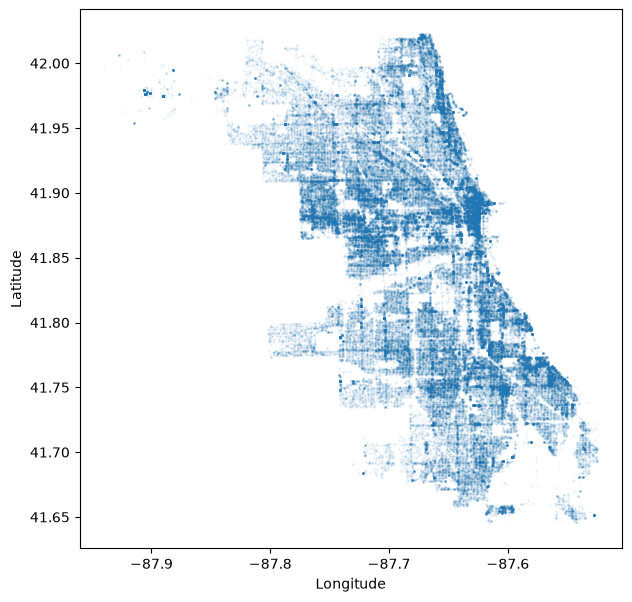

In [3]:
df2.plot.scatter('Longitude', 'Latitude', cmap='viridis_r', s=0.5, alpha=.05, figsize=(7, 7))
plt.savefig('chicagoscatter')
plt.show()

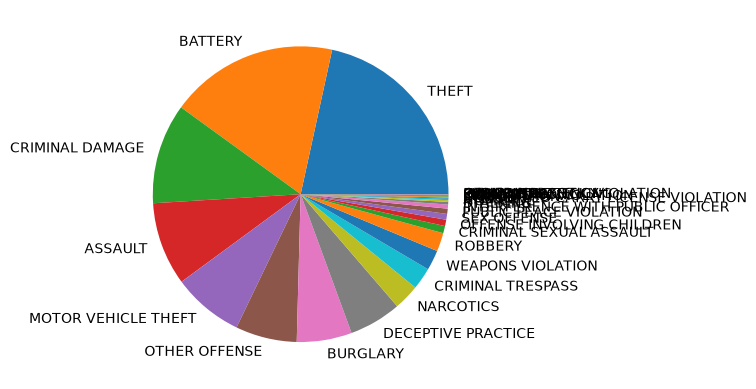

In [ ]:
df2['Primary Type'].value_counts().plot.pie()
plt.savefig('chicagopie')

In [12]:
fig = px.parallel_categories(
    df2,
    dimensions=['Arrest','Primary Type','Domestic'], 
    color=df2['Primary Type'].cat.codes,
    color_continuous_scale=px.colors.qualitative.Set1,
    width=800, height=450,
)
fig.update_traces(line_shape='hspline')
fig.update_layout(coloraxis_showscale=False)
fig.show()
plt.savefig('alluvial')

<Figure size 640x480 with 0 Axes>

In [29]:
df2['newcol'] = df2['newcol'].astype("category")

In [28]:
df2['Primary Type'] = df2['Primary Type'].astype("category")
df2.info()
top_categories = df['Primary Type'].value_counts().nlargest(10).index
print(top_categories)
df2.loc[~df['Primary Type'].isin(top_categories), "newcol"] = "OTHER OFFENSE"
df2.loc[df['Primary Type'].isin(top_categories), "newcol"] = df2['Primary Type']

<class 'pandas.DataFrame'>
RangeIndex: 189983 entries, 0 to 189982
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   ID                    189983 non-null  int64   
 1   Date                  189983 non-null  str     
 2   Block                 189983 non-null  str     
 3   Primary Type          189983 non-null  category
 4   Description           189983 non-null  str     
 5   Location Description  189128 non-null  str     
 6   Arrest                189983 non-null  bool    
 7   Domestic              189983 non-null  bool    
 8   Beat                  189983 non-null  int64   
 9   District              189983 non-null  int64   
 10  Ward                  189983 non-null  float64 
 11  FBI Code              189983 non-null  str     
 12  X Coordinate          189595 non-null  float64 
 13  Y Coordinate          189595 non-null  float64 
 14  Year                  189983 non-null  int64   

In [21]:
df2.head()

,ID,Date,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,FBI Code,X Coordinate,Y Coordinate,Year,Latitude,Longitude,newcol
0,14368435,10/24/2026 12:00:00 AM,042XX N MARINE DR,CRIMINAL TRESPASS,TO RESIDENCE,RESIDENCE,False,False,1915,19,46.0,26,1170986.0,1928779.0,2026,41.960047,-87.646762,OTHER OFFENSE
1,14373382,10/24/2026 12:00:00 AM,103XX S VERNON AVE,OTHER OFFENSE,TELEPHONE THREAT,RESIDENCE,False,False,512,5,9.0,08A,1181072.0,1836493.0,2026,41.706580,-87.612529,OTHER OFFENSE
2,14368301,10/24/2026 12:00:00 AM,085XX S CHAPPEL AVE,ASSAULT,AGGRAVATED - OTHER FIREARM,STREET,False,False,412,4,8.0,04A,1191334.0,1848657.0,2026,41.739717,-87.574557,ASSAULT
3,14372254,10/24/2026 12:00:00 AM,0000X N UNKNOWN AVE,CRIMINAL SEXUAL ASSAULT,NON-AGGRAVATED,OTHER (SPECIFY),False,False,6100,61,0.0,02,NaN,NaN,2026,NaN,NaN,OTHER OFFENSE
4,14368588,10/24/2026 12:00:00 AM,096XX S HOUSTON AVE,CRIMINAL DAMAGE,TO PROPERTY,RESIDENCE - GARAGE,False,False,431,4,10.0,14,1198192.0,1841661.0,2026,41.720351,-87.549665,CRIMINAL DAMAGE


In [34]:
df2['newcol'] = df2['newcol'].astype("category")
fig = px.parallel_categories(
    df2,
    dimensions=['newcol','Arrest'], 
    color=df2['newcol'].cat.codes,
    color_continuous_scale=px.colors.qualitative.Set1,
    width=800, height=450,
)
fig.update_traces(line_shape='hspline')
fig.update_layout(coloraxis_showscale=False)
fig.show()
plt.savefig('alluvial')

<Figure size 640x480 with 0 Axes>

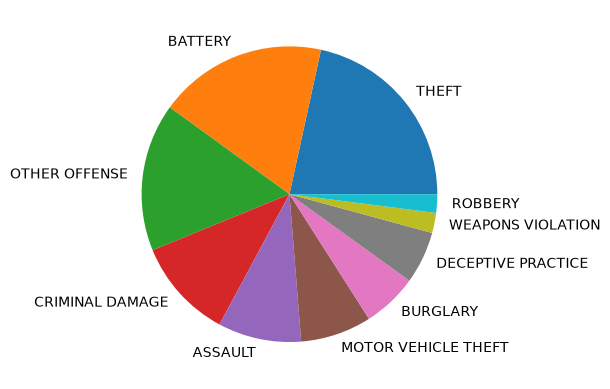

In [32]:
df2['newcol'].value_counts().plot.pie()
plt.savefig('pieplot2chicagocrime')